# Phase 3 — Understand and Inspect the Models
**Goal:** implement the generator and discriminator, trace their shapes, and inspect an **untrained** generator output.

No optimizer, training loop, pretrained weights, or quality claim is included here. Use the T4 GPU runtime. Phase 2 should already have saved the split manifest and cached DIV2K archives on Drive.

The default generator follows an SRResNet-style design with 16 residual blocks. Implementation choices are documented in the README.


## 1. Update the project
This updates a clean main checkout without resetting local edits. New model modules are loaded after the update.


In [1]:
from pathlib import Path
import importlib
import json
import os
import subprocess
import sys

PROJECT_ROOT = Path("/content/SRGAN-Image-Super-Resolution")
REPO_URL = "https://github.com/ennaguiyoussef/SRGAN-Image-Super-Resolution.git"
if not PROJECT_ROOT.exists():
    subprocess.run(["git", "clone", "--branch", "main", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    if not (PROJECT_ROOT / ".git").is_dir():
        raise RuntimeError("Project folder exists but is not a Git checkout.")
    changes = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "status", "--porcelain", "--untracked-files=no"],
        text=True,
    )
    if changes.strip():
        raise RuntimeError("Save local tracked edits before updating this checkout.")
    branch = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "branch", "--show-current"], text=True
    ).strip()
    if branch != "main":
        raise RuntimeError("Select the main branch before running this notebook.")
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only", "origin", "main"], check=True)
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
importlib.invalidate_caches()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("Project checkout ready.")


Project checkout ready.


## 2. Initialize fresh models on the GPU
LR is in [0, 1]. Both generated SR and reference HR are in [-1, 1]. The discriminator receives that same range for both sources.


In [2]:
import torch
from src.setup import environment_report, load_config, seed_everything
from src.models import Generator, Discriminator

config = load_config(PROJECT_ROOT / "configs/srgan.yaml")
seed_everything(config["seed"])
report = environment_report()
print(json.dumps(report, indent=2))
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime before continuing.")
device = torch.device("cuda:0")
generator = Generator().to(device)
discriminator = Discriminator().to(device)
generator.eval()
discriminator.eval()
for name, model in [("Generator", generator), ("Discriminator", discriminator)]:
    print(f"{name}: {sum(p.numel() for p in model.parameters()):,} trainable parameters")
print("Fresh random weights. No checkpoint has been loaded.")


{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "cuda_runtime": "13.0",
  "cuda_available": true,
  "gpu": "Tesla T4"
}
Generator: 1,550,659 trainable parameters
Discriminator: 23,565,505 trainable parameters
Fresh random weights. No checkpoint has been loaded.


## 3. Generator: follow one batch
| Stage | Output shape |
| --- | --- |
| LR input | (16, 3, 24, 24) |
| 9x9 convolution + PReLU | (16, 64, 24, 24) |
| 16 residual blocks | (16, 64, 24, 24) |
| Trunk convolution + BN + long skip | (16, 64, 24, 24) |
| Upsample block 1 | (16, 64, 48, 48) |
| Upsample block 2 | (16, 64, 96, 96) |
| 9x9 convolution + Tanh | (16, 3, 96, 96) |

Each residual block computes **x + F(x)**. The long skip also preserves early features. Both upsample blocks perform **Conv 64→256 → PixelShuffle(2) → PReLU**. PixelShuffle rearranges values; its preceding convolution learns them.

Batch normalization has running statistics; `eval()` keeps those fixed during inspection. It does not turn random weights into learned weights.


In [3]:
shapes = {}
handles = []
def record_shape(name):
    def hook(module, inputs, output):
        shapes[name] = list(output.shape)
    return hook

for name in ("head", "residual_blocks", "trunk", "upsample1", "upsample2", "output"):
    handles.append(getattr(generator, name).register_forward_hook(record_shape(name)))

try:
    with torch.inference_mode():
        synthetic_lr = torch.rand(16, 3, 24, 24, device=device)
        synthetic_sr = generator(synthetic_lr)
finally:
    for handle in handles:
        handle.remove()

for name, shape in shapes.items():
    print(f"{name:18s} -> {tuple(shape)}")
assert tuple(synthetic_sr.shape) == (16, 3, 96, 96)
assert torch.isfinite(synthetic_sr).all()
assert synthetic_sr.min().item() >= -1 and synthetic_sr.max().item() <= 1
print("Generator shape and range checks passed.")


head               -> (16, 64, 24, 24)
residual_blocks    -> (16, 64, 24, 24)
trunk              -> (16, 64, 24, 24)
upsample1          -> (16, 64, 48, 48)
upsample2          -> (16, 64, 96, 96)
output             -> (16, 3, 96, 96)
Generator shape and range checks passed.


## 4. Discriminator: one score per image
The discriminator reduces spatial resolution while increasing channels:
**96 → 48 → 24 → 12 → 6** pixels, with up to 512 feature channels.

Its dense classifier returns one **raw logit** per image, shape `(N, 1)`. There is no final sigmoid because future training will use `BCEWithLogitsLoss`, which incorporates it internally. A sigmoid can be used for display, but scores from an untrained discriminator have no useful real/fake interpretation.

This discriminator is fixed to **96x96** training crops. Only the generator is needed for future super-resolution inference.


In [4]:
with torch.inference_mode():
    synthetic_hr = torch.rand(16, 3, 96, 96, device=device) * 2 - 1
    real_logits = discriminator(synthetic_hr)
    fake_logits = discriminator(synthetic_sr)
assert tuple(real_logits.shape) == (16, 1)
assert tuple(fake_logits.shape) == (16, 1)
assert torch.isfinite(real_logits).all() and torch.isfinite(fake_logits).all()
print("Discriminator real batch:", tuple(real_logits.shape))
print("Discriminator generated batch:", tuple(fake_logits.shape))
print("Discriminator shape checks passed. These scores do not measure image quality.")
del synthetic_lr, synthetic_sr, synthetic_hr, real_logits, fake_logits


Discriminator real batch: (16, 1)
Discriminator generated batch: (16, 1)
Discriminator shape checks passed. These scores do not measure image quality.


## 5. Restore validation images and the saved split
Mount Drive. If Colab storage was reset, this restores only the validation HR archive from the phase-2 cache. It does not redownload the training set or access held-out test image contents.


In [5]:
from google.colab import drive
from src.setup import prepare_directories
from src.data import extract_hr_archive, split_manifest
from src.dataset import SuperResolutionDataset

drive.mount("/content/drive")
OUTPUT_ROOT = Path("/content/drive/MyDrive/SRGAN-Image-Super-Resolution")
paths = prepare_directories(PROJECT_ROOT, OUTPUT_ROOT)
DATA_ROOT = paths["data"] / "DIV2K"
manifest_path = OUTPUT_ROOT / "splits" / "div2k_seed42.json"
if not manifest_path.is_file():
    raise RuntimeError("Saved split is missing. Complete phase 2 first.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
if manifest != split_manifest(config["seed"]):
    raise RuntimeError("Saved split does not match the current seed. Use the phase-2 configuration.")
validation_names = manifest["validation"]
if not all((DATA_ROOT / name).is_file() for name in validation_names):
    archive = OUTPUT_ROOT / "dataset_cache" / "DIV2K_valid_HR.zip"
    if not archive.is_file():
        raise RuntimeError("Validation archive cache is missing. Rerun phase 2 to restore it.")
    validation_ids = [int(Path(name).stem) for name in validation_names]
    extract_hr_archive(archive, DATA_ROOT, "DIV2K_valid_HR", validation_ids)
validation_dataset = SuperResolutionDataset(
    DATA_ROOT, validation_names, hr_size=config["hr_crop_size"],
    scale=config["scale_factor"], training=False,
)
print("Validation images ready:", len(validation_dataset))


Mounted at /content/drive
Validation images ready: 50


## 6. Compare LR, bicubic, untrained SR, and HR
An untrained generator may output flat colors, patterns, or noise. This is expected: correct dimensions do not imply learned reconstruction.

We display SR/HR with **(x + 1) / 2** because they are in [-1, 1]. LR is already in [0, 1].


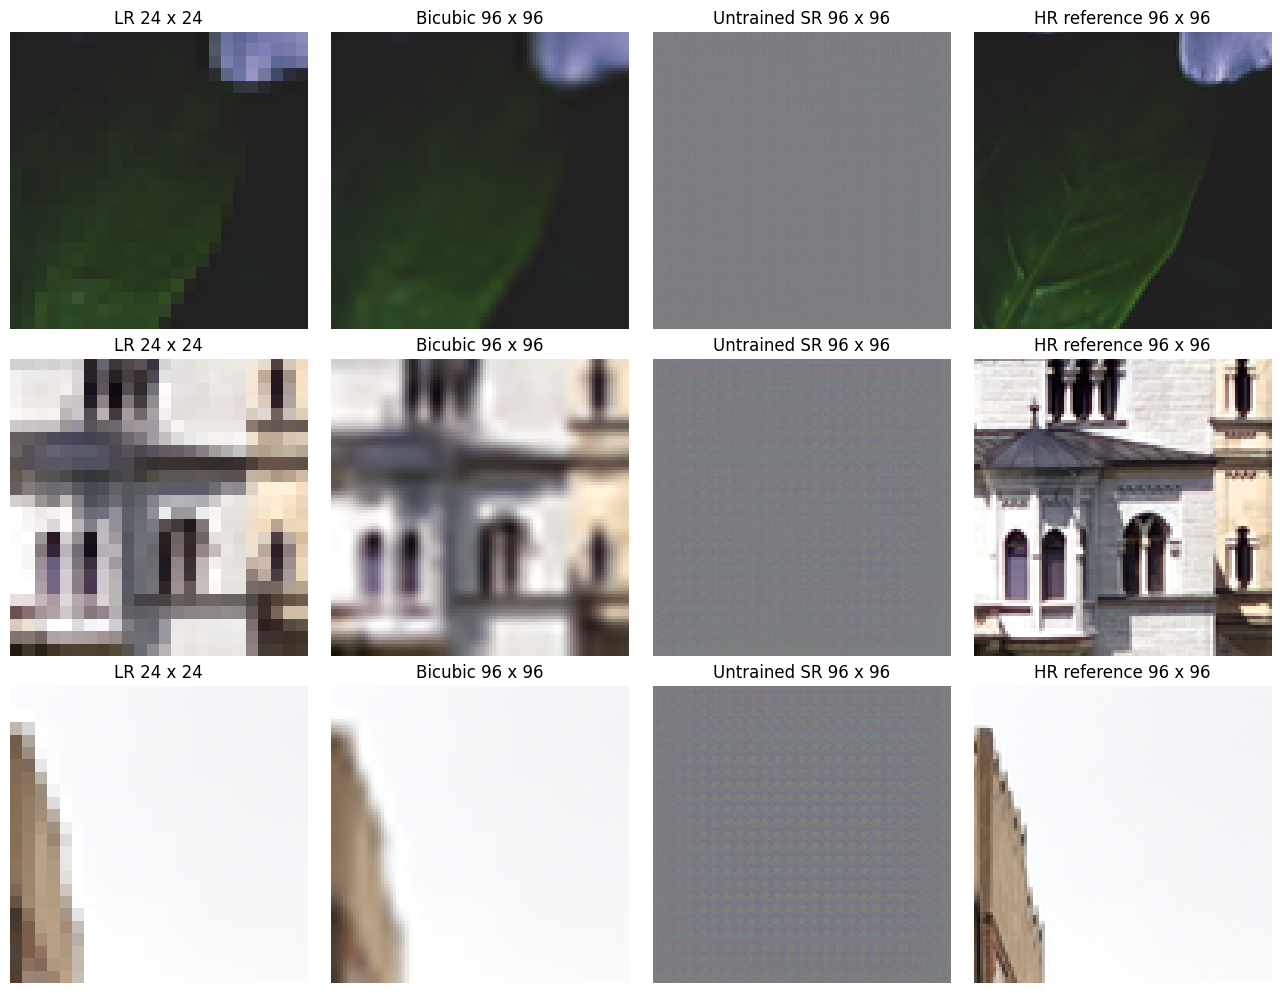

Saved preview: /content/drive/MyDrive/SRGAN-Image-Super-Resolution/results/phase3_untrained_generator.png


In [6]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

preview_pairs = [validation_dataset[i] for i in range(3)]
preview_lr = torch.stack([pair[0] for pair in preview_pairs]).to(device)
with torch.inference_mode():
    preview_sr = generator(preview_lr).cpu()

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for row, (lr, hr) in enumerate(preview_pairs):
    lr_image = lr.permute(1, 2, 0).numpy()
    bicubic = Image.fromarray(np.rint(lr_image * 255).astype(np.uint8)).resize(
        (96, 96), Image.Resampling.BICUBIC
    )
    sr_image = ((preview_sr[row] + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy()
    hr_image = ((hr + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy()
    panels = [
        (lr_image, "LR 24 x 24"), (bicubic, "Bicubic 96 x 96"),
        (sr_image, "Untrained SR 96 x 96"), (hr_image, "HR reference 96 x 96"),
    ]
    for col, (image, title) in enumerate(panels):
        axes[row, col].imshow(image, interpolation="nearest")
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
fig.tight_layout()
preview_path = paths["results"] / "phase3_untrained_generator.png"
fig.savefig(preview_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved preview:", preview_path)


## 7. Save the inspection report
The report records architecture, shape checks, runtime, and current commit. No model weights or training checkpoints are saved in this phase.


In [7]:
report.update({
    "git_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
    "config": config,
    "generator_parameters": sum(p.numel() for p in generator.parameters()),
    "discriminator_parameters": sum(p.numel() for p in discriminator.parameters()),
    "generator_shapes": shapes,
    "generator_residual_blocks": 16,
    "generator_channels": 64,
    "generator_output_activation": "Tanh",
    "discriminator_output": "raw logits (N, 1)",
    "trained": False,
})
(paths["logs"] / "phase3_model_inspection.json").write_text(
    json.dumps(report, indent=2) + "\n", encoding="utf-8"
)
print("Phase 3 complete: generator, discriminator, and untrained visualization checks passed.")


Phase 3 complete: generator, discriminator, and untrained visualization checks passed.


## Next step
Why can the untrained generator produce the correct image size while failing to reproduce the reference details?

Next: Phase 4 — pretrain the generator with pixel loss before introducing adversarial training. No training has started yet.
